##### Copyright 2024 Google LLC.

In [ ]:
# @title Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at
#
# https://www.apache.org/licenses/LICENSE-2.0
#
# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.

# PaliGemma - Common use cases
This notebook demonstrates the basic task that Gemma can solve by using the right prompting.
<table align="left">
  <td>
    <a target="_blank" href="https://colab.research.google.com/github/google-gemma/cookbook/blob/main/.archive/PaliGemma/[PaliGemma_1]Common_use_cases.ipynb"><img src="https://www.tensorflow.org/images/colab_logo_32px.png" />Run in Google Colab</a>
  </td>
</table>

## Setup

### Select the Colab runtime
To complete this tutorial, you'll need to have a Colab runtime with sufficient resources to run the Gemma model. In this case, you can use a T4 GPU:

1. In the upper-right of the Colab window, select **▾ (Additional connection options)**.
2. Select **Change runtime type**.
3. Under **Hardware accelerator**, select **T4 GPU**.

### Gemma setup

To complete this tutorial, you'll first need to complete the setup instructions at [Gemma setup](https://gemma.ai/get-started/). The Gemma setup instructions show you how to do the following:

* Get access to Gemma on kaggle.com.
* Select a Colab runtime with sufficient resources to run
  the Gemma 2B model.
* Generate and configure a Kaggle username and an API key as Colab secrets.

After you've completed the Gemma setup, move on to the next section, where you'll set environment variables for your Colab environment.


### Configure your credentials

Add your your Kaggle credentials to the Colab Secrets manager to securely store it.

1. Open your Google Colab notebook and click on the 🔑 Secrets tab in the left panel. <img src="https://storage.googleapis.com/generativeai-downloads/images/secrets.jpg" alt="The Secrets tab is found on the left panel." width=50%>
2. Create new secrets: `KAGGLE_USERNAME` and `KAGGLE_KEY`
3. Copy/paste your username into `KAGGLE_USERNAME`
3. Copy/paste your key into `KAGGLE_KEY`
4. Toggle the buttons on the left to allow notebook access to the secrets.


In [ ]:
import os
from google.colab import userdata

# Note: `userdata.get` is a Colab API. If you're not using Colab, set the env
# vars as appropriate for your system.
os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")

### Install dependencies
Run the cell below to install all the required dependencies.

In [ ]:
!pip install -q -U keras keras-nlp

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 9.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 570.5/570.5 kB 15.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 311.2/311.2 kB 3.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 950.8/950.8 kB 14.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.2/5.2 MB 17.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 589.8/589.8 MB 2.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 81.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 95.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 85.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tf-keras 2.15.1 requires tensorflow<2.16,>=2.15, but you have tensorflow 2.16.1 which is incompatible

## Exploring prompting capabilities

### PaliGemma

PaliGemma is a lightweight open vision-language model (VLM) inspired by PaLI-3, and based on open components like the SigLIP vision model and the Gemma language model. PaliGemma takes both images and text as inputs and can answer questions about images with detail and context, meaning that PaliGemma can perform deeper analysis of images and provide useful insights, such as captioning for images and short videos, object detection, and reading text embedded within images.

Prompting:

* `cap {lang}\n`: Very raw short caption (from WebLI-alt)
* `caption {lang}\n`: Nice, COCO-like short captions
* `describe {lang}\n`: Somewhat longer, more descriptive captions
* `ocr`: Optical character recognition
* `answer en {question}\n`: Question answering about the image contents
* `question {lang} {answer}\n`: Question generation for a given answer
* `detect {object} ; {object}\n`: Count objects in a scene and return the bounding boxes for the objects
* `segment {object}\n`: Do image segmentation of the object in the scene

In [ ]:
import os
import keras
import keras_nlp
from google.colab import userdata

keras.config.set_floatx("bfloat16")
os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")

In [ ]:
# Load PaliGemma
paligemma = keras_nlp.models.PaliGemmaCausalLM.from_preset("pali_gemma_3b_mix_224")

100%|██████████| 861/861 [00:00<00:00, 782kB/s]
100%|██████████| 5.45G/5.45G [03:14<00:00, 30.1MB/s]
100%|██████████| 410/410 [00:00<00:00, 302kB/s]
100%|██████████| 4.07M/4.07M [00:00<00:00, 6.34MB/s]


In [ ]:
import io
import re
import PIL
import requests
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Helpers:

headers = {"User-Agent": "My User Agent 1.0"}


def crop_and_resize(image, target_size):
    """A helper function the resizes given image to the given shape"""
    width, height = image.size
    source_size = min(image.size)
    left = width // 2 - source_size // 2
    top = height // 2 - source_size // 2
    right, bottom = left + source_size, top + source_size
    return image.resize(target_size, box=(left, top, right, bottom))


def read_image(url, target_size=(224, 224)):
    """Loads images from URL"""
    contents = io.BytesIO(requests.get(url, headers=headers, stream=True).content)
    image = Image.open(contents)
    image = crop_and_resize(image, target_size)
    image = np.array(image)

    # Remove alpha channel if neccessary.
    if image.shape[2] == 4:
        image = image[:, :, :3]
    return image


def parse_bbox_and_labels(detokenized_output: str):
    """Parses model output to extract bounding boxes"""
    matches = re.finditer(
        "<loc(?P<y0>\d\d\d\d)><loc(?P<x0>\d\d\d\d)><loc(?P<y1>\d\d\d\d)><loc(?P<x1>\d\d\d\d)>"
        " (?P<label>.+?)( ;|$)",
        detokenized_output,
    )
    labels, boxes = [], []
    fmt = lambda x: float(x) / 1024.0
    for m in matches:
        d = m.groupdict()
        boxes.append([fmt(d["y0"]), fmt(d["x0"]), fmt(d["y1"]), fmt(d["x1"])])
        labels.append(d["label"])
    return np.array(boxes), np.array(labels)


def display_boxes(image, boxes, labels, target_image_size):
    """Draws bouding boxes on the given image"""
    h, l = target_image_size
    fig, ax = plt.subplots()
    ax.imshow(image)
    for i in range(boxes.shape[0]):
        y, x, y2, x2 = boxes[i] * h
        width = x2 - x
        height = y2 - y
        # Create a Rectangle patch
        rect = patches.Rectangle(
            (x, y), width, height, linewidth=1, edgecolor="r", facecolor="none"
        )
        # Add label
        plt.text(x, y, labels[i], color="red", fontsize=12)
        # Add the patch to the Axes
        ax.add_patch(rect)

    plt.show()

#### Prompting example: Visual Question Answering

array([[[123, 122, 113],
        [ 91,  91,  69],
        [ 89,  92,  65],
        ...,
        [ 67,  76,  40],
        [ 54,  64,  28],
        [ 66,  76,  41]],

       [[ 90,  88,  76],
        [ 83,  83,  65],
        [ 89,  92,  73],
        ...,
        [ 60,  69,  34],
        [ 49,  60,  26],
        [ 61,  72,  38]],

       [[112, 121, 112],
        [143, 152, 152],
        [152, 163, 165],
        ...,
        [ 74,  89,  49],
        [ 70,  85,  44],
        [ 74,  89,  50]],

       ...,

       [[127, 175,  86],
        [129, 179,  87],
        [123, 171,  80],
        ...,
        [117, 165,  74],
        [133, 179,  87],
        [131, 176,  92]],

       [[157, 200, 107],
        [149, 195,  99],
        [146, 195,  97],
        ...,
        [154, 200, 112],
        [131, 177,  90],
        [133, 183,  99]],

       [[172, 217, 124],
        [152, 200, 105],
        [150, 202, 105],
        ...,
        [168, 218, 125],
        [148, 196, 110],
        [139, 190, 101]]], dtype=uint8)
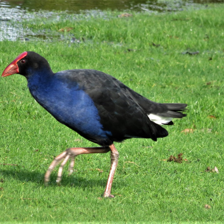

In [ ]:
# Image by: Wainuio, CC BY-SA 4.0, via Wikimedia Commons
image_url = "https://upload.wikimedia.org/wikipedia/commons/8/8b/Bird-8077%2C_Kapiti%2C_North_Island%2C_New_Zealand.jpg"
image = read_image(image_url)
image

In [ ]:
# Describing the image
prompt = "describe en\n"
output = paligemma.generate(
    inputs={
        "images": image,
        "prompts": prompt,
    }
)
print(output[len(prompt) :])

In this image we can see a bird on the ground. In the background there is water.


In [ ]:
# Answering questions about the image
prompt = "answer en is the bird flying?\n"
output = paligemma.generate(
    inputs={
        "images": image,
        "prompts": prompt,
    }
)
print(output[len(prompt) :])

no


In [ ]:
# Answering detailed questions about the image
prompt = "answer en What's the color of the beak?\n"
output = paligemma.generate(
    inputs={
        "images": image,
        "prompts": prompt,
    }
)
print(output[len(prompt) :])

red


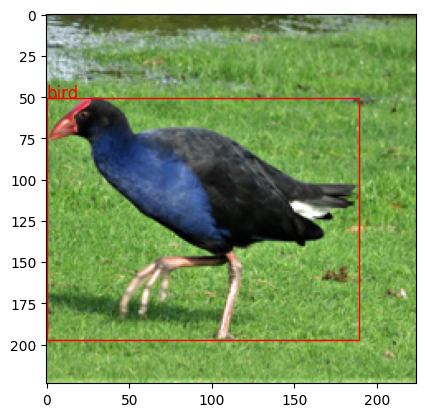

In [ ]:
# Object detection
prompt = "detect bird\n"
output = paligemma.generate(
    inputs={
        "images": image,
        "prompts": prompt,
    }
)
boxes, labels = parse_bbox_and_labels(output)
display_boxes(image, boxes, labels, (224, 224))

#### Prompting example: Optical Rharacter Recognition (OCR)

array([[[ 51,  80, 109],
        [ 44,  79, 110],
        [ 50,  83, 111],
        ...,
        [100,  85,  92],
        [ 99,  87,  96],
        [ 98,  88,  98]],

       [[112, 146, 163],
        [112, 147, 163],
        [116, 152, 165],
        ...,
        [111, 140, 157],
        [112, 142, 159],
        [111, 143, 161]],

       [[192, 200, 204],
        [191, 200, 204],
        [192, 201, 204],
        ...,
        [183, 194, 203],
        [183, 194, 202],
        [184, 195, 203]],

       ...,

       [[185, 186, 178],
        [185, 186, 177],
        [186, 187, 177],
        ...,
        [190, 185, 166],
        [189, 187, 168],
        [189, 187, 169]],

       [[161, 166, 139],
        [156, 162, 135],
        [155, 161, 133],
        ...,
        [125, 128,  91],
        [128, 129,  94],
        [131, 133,  96]],

       [[ 56,  54,  37],
        [ 55,  51,  35],
        [ 53,  48,  32],
        ...,
        [ 72,  50,  29],
        [ 72,  50,  29],
        [ 69,  50,  26]]], dtype=uint8)
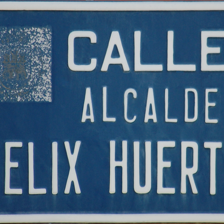

In [ ]:
# Image by: Raimundo Pastor, CC BY-SA 4.0, via Wikimedia Commons
image_url = "https://upload.wikimedia.org/wikipedia/commons/1/1b/Alcal%C3%A1_de_Henares_%28RPS_08-04-2017%29_Calle_Alcalde_F%C3%A9lix_Huerta%2C_placa_indicativa.png"
image = read_image(image_url)
image

In [ ]:
prompt = "ocr"
output = paligemma.generate(
    inputs={
        "images": image,
        "prompts": prompt,
    }
)
print(output[len(prompt) :])

 CALLE ALCALDE
ELIX HUERT
